# Part I

Here we plot and work with symbolic differentiation of multidimensional functions

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
import sympy as sym

The following code demonstrates how to plot functions of two variables in three dimensions. The `meshgrid` command creates a two-dimensional grid. The function is then evluated at the grid points and plotted. I also included additional code for a colorbar that indicates the value of the function for each color in the plot.

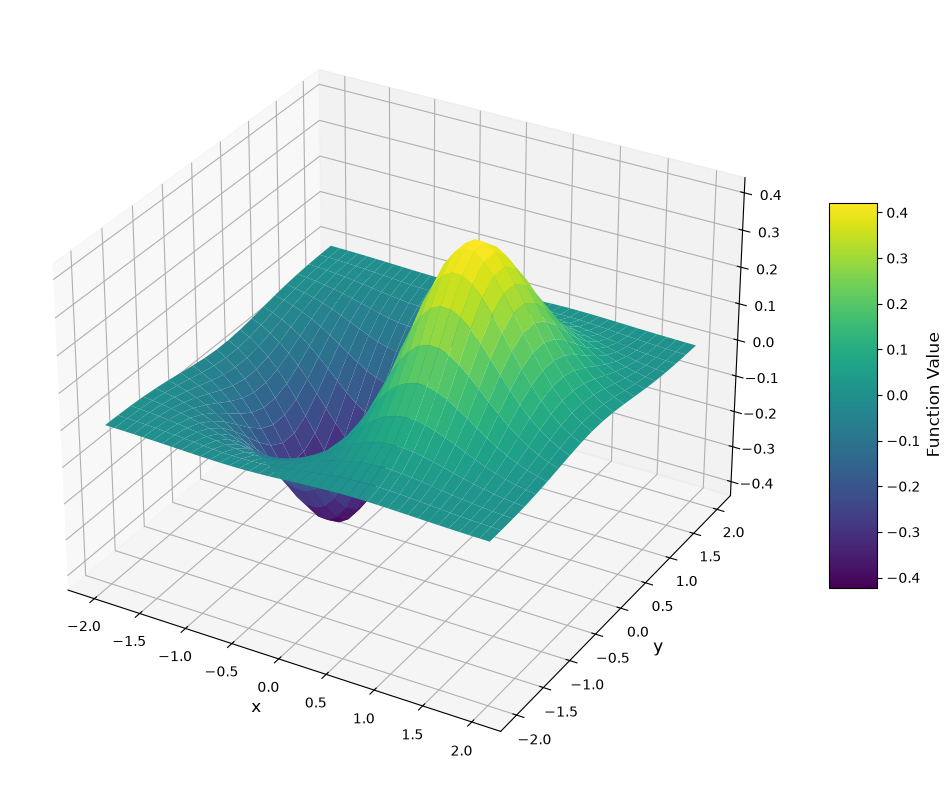

In [17]:
def my_function(x, y):
    return x*np.exp(-x**2 - y**2)


x = np.linspace(-2, 2, 40)
y = np.linspace(-2, 2, 20)

X, Y = np.meshgrid(x, y)
Z = my_function(X, Y)

fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection='3d')

surface = ax.plot_surface(X, Y, Z, cmap='viridis')
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y', fontsize=12)



cbar = fig.colorbar(surface, ax=ax, shrink=0.5, aspect=8)
cbar.set_label('Function Value', fontsize=12)
plt.tight_layout()


plt.show()

**Problem 1** By looking at the structure of `X` and `Y` that are returned from `meshgrid`, describe what this function does.  

**Problem 2** Plot the function `sin(xy)` with `x` and `y` each in the interval `[-3,3]`. Try to get a reasonably smooth plot. (You can increase the resolution in the `linspace` command if the plot looks too blocky.)

Recall your work with symbolic differentiation on the previous lab.  It works here too.

In [18]:
x, y, z = sym.symbols('x y z') #you only need to declare which symbols are variables once

In [19]:
my_expression = x**3 * y + y**3 + z

# Take partial derivatives

derivative1_x = sym.diff(my_expression, x)
print(derivative1_x)

derivative1_z = sym.diff(my_expression, z)
print(derivative1_z)

3*x**2*y
1


In [20]:
# evaluate at a point
point = {x: 1, y: 1, z: 1}
value = derivative1_x.subs(point)
print(value)

3


In [21]:
# take higher derivatives
derivative2_x = sym.diff(my_expression, x, 2)
print(derivative2_x)

6*x*y


**Problem 3** Symbolically take the two partial derivative of $ e^{xy}$ and evaluate at the point $(1/2, 3)$.  Use `sym.exp` for the exponential function.

In [22]:
expr = sym.exp(x * y)

d_dx = sym.diff(expr, x)
d_dy = sym.diff(expr, y)

print("df/dx =", d_dx)
print("df/dy =", d_dy)

point = {x: sym.Rational(1, 2), y: 3}
print("df/dx at (1/2, 3) =", d_dx.subs(point), "=", float(d_dx.subs(point)))
print("df/dy at (1/2, 3) =", d_dy.subs(point), "=", float(d_dy.subs(point)))


df/dx = y*exp(x*y)
df/dy = x*exp(x*y)
df/dx at (1/2, 3) = 3*exp(3/2) = 13.445067211014194
df/dy at (1/2, 3) = exp(3/2)/2 = 2.2408445351690323


**Problem 4** Symbolically find $f_{xx}$, $f_{xy}$, $f_{yx}$, and $f_{yy}$ for $f=\frac{4x^2}{y} + \frac{y^2}{2x}$

In [23]:
f = 4*x**2/y + y**2/(2*x)

f_xx = sym.diff(f, x, 2)
f_xy = sym.diff(f, x, y)
f_yx = sym.diff(f, y, x)
f_yy = sym.diff(f, y, 2)

print("f_xx =", f_xx)
print("f_xy =", f_xy)
print("f_yx =", f_yx)
print("f_yy =", f_yy)


f_xx = 8/y + y**2/x**3
f_xy = -(8*x/y**2 + y/x**2)
f_yx = -(8*x/y**2 + y/x**2)
f_yy = 8*x**2/y**3 + 1/x


## Part II

The following problems ask to you implement the gradient descent algorithm in one dimension and explore some of its properties.

### Goal: minimizing the function

Suppose our goal is to minimize a function and we don't know what the minimizer is. Suppose we initially start at point $\mathbf{x}_0 = \mathbf{a} = (1,1)$. Then using our understanding of the role of the gradient, one method is to *iteratively* move in the direction of the *negative* of the gradient, i.e. at each step $t$, if our current position is $\mathbf{x}_t$ then we do the update

$$\mathbf{x}_{t+1} = \mathbf{x}_t - \eta \nabla f(\mathbf{x}_t)$$

where $\eta$ is the "small" move in the direction of the negative of the gradient and is often called the *learning* rate.


**Problem 5** Write a function with two arguments, a learning rate parameter and an initial guess. The function should perform 10 iterations of gradient descent with `f(x) = x^2/2` and the given initial guess, then return the resulting value. Print the result of the function applied with initial value 10 and the following learning rates: 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 3. The gradient descent calculations/iterations should be written out explicitly; don't just call a library function.



In [24]:
def gd(learning_rate, initial_guess):
    x = initial_guess
    for _ in range(10):
        gradient = x  # f'(x) = x for f(x) = x^2/2
        x = x - learning_rate * gradient
    return x

learning_rates = [0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 3]
for lr in learning_rates:
    print(f"learning rate {lr:.2f}: x = {gd(lr, 10):.6f}")


learning rate 0.25: x = 0.563135
learning rate 0.50: x = 0.009766
learning rate 0.75: x = 0.000010
learning rate 1.00: x = 0.000000
learning rate 1.25: x = 0.000010
learning rate 1.50: x = 0.009766
learning rate 1.75: x = 0.563135
learning rate 2.00: x = 10.000000
learning rate 3.00: x = 10240.000000


**Problem 6** Which learning rate gives the most accurate value for the minimum? Which gives the last accurate value? (You may wish to look at the discussion of the rate of convergence for gradient descent for this function in the notes. The answers can also be deduced from the analysis there.)

**Problem 7** Consider the function `f(x)= x^4 - 4x^2 + x`. Use gradient descent to find the value of `x` that achieves the global minimum, and the value of `f(x)` at that point. Print both values. To get full points, you must get the first three digits of each number right. (For example, if the true minimizer is 3.1415..., then your answer must begin 3.14... to get full credit.)

The gradient descent calculations/iterations should be written out explicitly; don't just call a library function.

**Hint 1.** This function is not convex, so it is possible for gradient descent to converge to the wrong local minimum.

**Hint 2.** Choosing a good learning rate is crucial here. If it is too large, it won't converge. You will need values a bit smaller than the previous example. Try a range of values. If you try many small learning rate parameters and they all give the same result, this should increase your confidence in your answer. Also, try increasing the number of iterations.

**Problem 8** Let's move to 2D.  Add the lines of code for the gradient and the implimentation of gradient descent.

In [25]:
# Function to minimize
def function(x, y):
    return x**2 + y**2

# Gradient of the function
def gradient(x, y):
    return np.array([2*x, 2*y])

# Gradient Descent
def gradient_descent(start_point, learning_rate, iterations):
    trajectory = [start_point]
    current_point = np.array(start_point, dtype=float)

    for _ in range(iterations):
        grad = gradient(*current_point)
        current_point = current_point - learning_rate * grad
        trajectory.append(current_point.tolist())

    return np.array(trajectory)


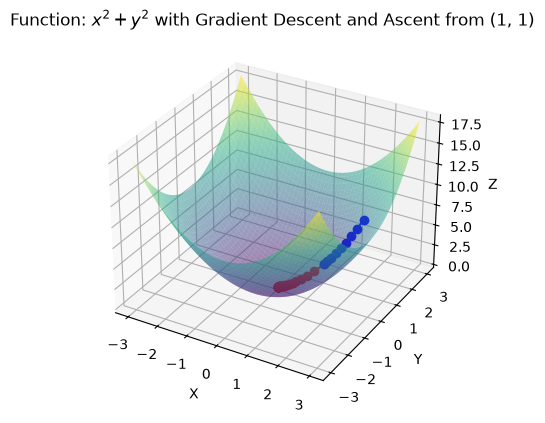

In [26]:
# Gradient Ascent
def gradient_ascent(start_point, learning_rate, iterations):
    trajectory = [start_point]
    current_point = np.array(start_point, dtype=float)

    for _ in range(iterations):
        grad = gradient(*current_point)
        current_point = current_point + learning_rate * grad
        trajectory.append(current_point.tolist())

    return np.array(trajectory)

# Starting point
start_point = [1, 1]  # (1, 1)

# Learning rate and number of iterations
learning_rate = 0.1
iterations_descent = 30

iterations_ascent = 8
learning_rate_ascent = 0.04

# Perform Gradient Descent and Gradient Ascent
descent_trajectory = gradient_descent(start_point, learning_rate, iterations_descent)
ascent_trajectory = gradient_ascent(start_point, learning_rate_ascent, iterations_ascent)

# Define a grid of points
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
Z = function(X, Y)

# Plotting
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.5)

# Plot the trajectory of gradient descent (in red)
descent_trajectory = np.array(descent_trajectory)
ax.plot(descent_trajectory[:, 0], descent_trajectory[:, 1], function(descent_trajectory[:, 0], descent_trajectory[:, 1]), marker='o', color='red')

# Plot the trajectory of gradient ascent (in blue)
ascent_trajectory = np.array(ascent_trajectory)
ax.plot(ascent_trajectory[:, 0], ascent_trajectory[:, 1], function(ascent_trajectory[:, 0], ascent_trajectory[:, 1]), marker='o', color='blue')

# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Title
plt.title('Function: $x^2 + y^2$ with Gradient Descent and Ascent from (1, 1)')

# Show plot
plt.show()


**Problem 9**
Modify the above code to understand the behavior now for the function

$$f(x,y) =.01*( x^6 + y^6 + 3)$$

You might need to modify the learning rates so you can actually see the iterations moving.

Final point: [0.24453889 0.24453889]
Final value: 0.030004276787234795


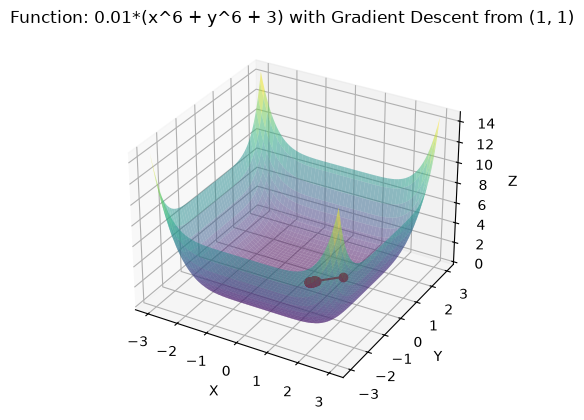

In [27]:
# Function to minimize
def function(x, y):
    return 0.01 * (x**6 + y**6 + 3)

# Gradient of the function
def gradient(x, y):
    return np.array([0.06 * x**5, 0.06 * y**5])

# Gradient Descent
def gradient_descent(start_point, learning_rate, iterations):
    trajectory = [start_point]
    current_point = np.array(start_point, dtype=float)

    for _ in range(iterations):
        grad = gradient(*current_point)
        current_point = current_point - learning_rate * grad
        trajectory.append(current_point.tolist())

    return np.array(trajectory)

# Starting point
start_point = [1, 1]

# Learning rate and number of iterations
learning_rate = 10
iterations = 100

# Perform Gradient Descent
trajectory = gradient_descent(start_point, learning_rate, iterations)
trajectory = np.array(trajectory)

print("Final point:", trajectory[-1])
print("Final value:", function(trajectory[-1, 0], trajectory[-1, 1]))

# Plotting
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a grid of points
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
Z = function(X, Y)

# Plot the surface
ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.5)

# Plot the trajectory
ax.plot(trajectory[:, 0], trajectory[:, 1], function(trajectory[:, 0], trajectory[:, 1]), marker='o', color='red')

# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Title
plt.title('Function: 0.01*(x^6 + y^6 + 3) with Gradient Descent from (1, 1)')

# Show plot
plt.show()
